# Customer Support Ticket Classification
### Team Batch 10, Project 6 | Natural Language Processing
**Course:** Data Science / Artificial Intelligence and Machine Learning  
**Application Domain:** Automated Customer Support Triage & Department Routing  
**Core Technologies:** Python, Pandas, NumPy, NLTK, Scikit-learn, Matplotlib, Seaborn, Joblib  

---

## Abstract
In high-volume customer service operations, incoming requests must be rapidly categorized to reach specialized support teams (Billing, Technical Support, Account Access, Order Issues, Refund/Returns, and General Inquiry). Manual routing is slow, expensive, and error-prone. This project presents a complete, production-grade Natural Language Processing (NLP) pipeline that classifies customer requests and computes calibrated confidence scores for automated routing and human-in-the-loop triage. 

Using a curated dataset of over 1,500 diverse customer inquiries, we build an end-to-end classical machine learning solution featuring:
1. **Negation-Preserving NLP Preprocessing** (WordNet Lemmatization + custom stopword whitelisting)
2. **Leakage-Free Feature Engineering** via encapsulated scikit-learn TF-IDF Pipelines
3. **Multi-Model Benchmark & 5-Fold Stratified Cross-Validation** comparing Multinomial Naive Bayes, Logistic Regression, and Calibrated Linear SVM
4. **Hyperparameter Optimization** using GridSearchCV
5. **Rigorous Error Analysis and Interpretability**, identifying lexical overlap boundaries
6. **Production Artifact Export** feeding a live Streamlit web application with confidence threshold gating.

## 1. Environment Setup & Library Ingestion
We import standard data science and NLP libraries. We configure a fixed random seed (`42`) across all components to guarantee 100% experimental reproducibility.

In [1]:
import os
import sys
import json
import joblib
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (10, 6)

# NLP & Machine Learning Libraries
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Project root detection that works whether run from root or notebooks/
PROJECT_ROOT = None
for candidate in [os.path.abspath('.'), os.path.abspath('..'), os.path.abspath('../..')]:
    if os.path.exists(os.path.join(candidate, 'data', 'tickets.csv')):
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    # Fallback to known workspace path
    PROJECT_ROOT = "C:/Users/wwwaj/.virtual_documents/Downloads/NLP GENAI"

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.preprocess import preprocess_text, clean_text

SEED = 42
np.random.seed(SEED)
print(f"Libraries imported successfully! Project Root: {PROJECT_ROOT}")

Libraries imported successfully! Project Root: C:\Users\wwwaj\.virtual_documents\Downloads\NLP GENAI


## 2. Dataset Ingestion and Structural Inspection
We load the curated dataset from `data/tickets.csv` and inspect its shape, column datatypes, and initial records.

In [2]:
data_path = os.path.join(PROJECT_ROOT, 'data', 'tickets.csv')
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nColumn Data Types:\n", df.dtypes)
print("\nFirst 5 Records:")
df.head()

Dataset Shape: 1528 rows, 3 columns

Column Data Types:
 ticket_id    object
text         object
category     object
dtype: object

First 5 Records:


,ticket_id,text,category
0,TCK-10001,"Hey team, The billing checkout page crashes wi...",Technical Support
1,TCK-10002,Urgent: double charged on card ending 9837,Billing
2,TCK-10003,"Hey team, I returned three items in one box, b...",Refund/Returns
3,TCK-10004,I cant access my acount to update our corporat...,Account Access
4,TCK-10005,exchange for a different size,Refund/Returns


## 3. Exploratory Data Analysis (EDA)

### 3.1 Data Integrity Checks: Missing Values & Duplicates
Before training any model, we must verify that there are no null fields or duplicate texts that could distort class distributions or cause train-test leakage.

In [3]:
print("Missing Values Summary:")
print(df.isnull().sum())

duplicate_count = df.duplicated(subset=['text']).sum()
print(f"\nDuplicate Tickets in Corpus: {duplicate_count}")

# Check class frequencies
class_counts = df['category'].value_counts()
print("\nClass Frequencies:\n", class_counts)

Missing Values Summary:
ticket_id    0
text         0
category     0
dtype: int64

Duplicate Tickets in Corpus: 0

Class Frequencies:
 category
Order Issues         259
Billing              258
Refund/Returns       256
Account Access       255
Technical Support    253
General Inquiry      247
Name: count, dtype: int64


### 3.2 Target Class Distribution
A balanced dataset ensures that our classifier does not develop a majority-class bias. Below is the distribution across all 6 customer service categories.

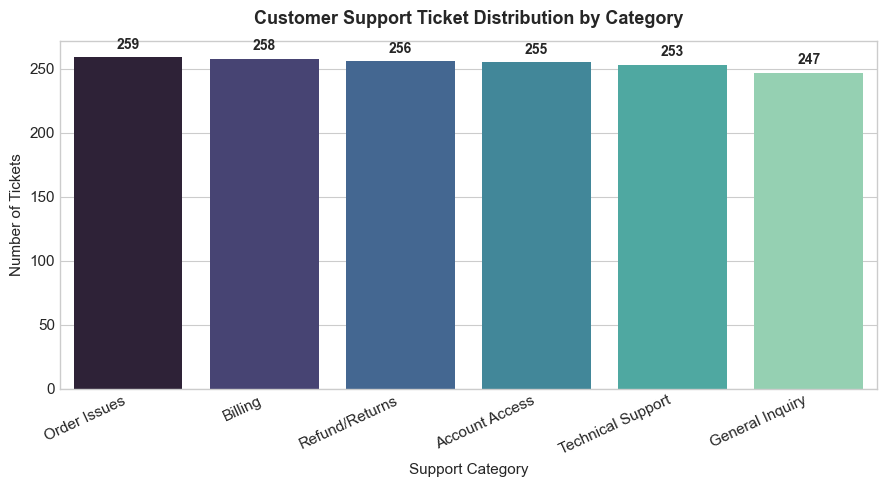

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
palette = sns.color_palette("mako", len(class_counts))
bars = sns.barplot(x=class_counts.index, y=class_counts.values, palette=palette, ax=ax)

ax.set_title("Customer Support Ticket Distribution by Category", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Support Category", fontsize=11)
ax.set_ylabel("Number of Tickets", fontsize=11)
plt.xticks(rotation=25, ha='right')

for bar in bars.patches:
    yval = bar.get_height()
    ax.annotate(f"{int(yval)}",
                xy=(bar.get_x() + bar.get_width() / 2, yval),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(PROJECT_ROOT, 'reports', 'class_distribution.png'), dpi=300)
plt.show()

### 3.3 Text Length Analysis (Character and Word Distributions)
Support tickets vary from short phrases to detailed complaints. We examine character length and word count distributions to understand sequence diversity.

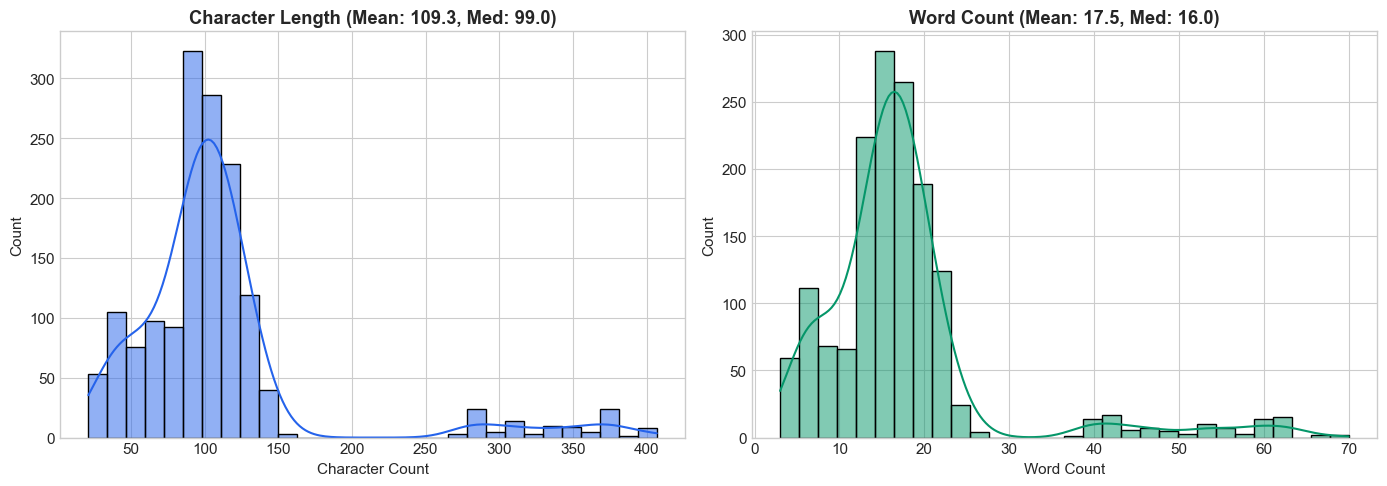

In [5]:
df['char_count'] = df['text'].astype(str).apply(len)
df['word_count'] = df['text'].astype(str).apply(lambda t: len(t.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Character length distribution
sns.histplot(df['char_count'], kde=True, ax=axes[0], color='#2563eb', bins=30)
axes[0].set_title(f"Character Length (Mean: {df['char_count'].mean():.1f}, Med: {df['char_count'].median():.1f})", fontweight='bold')
axes[0].set_xlabel("Character Count")

# Word count distribution
sns.histplot(df['word_count'], kde=True, ax=axes[1], color='#059669', bins=30)
axes[1].set_title(f"Word Count (Mean: {df['word_count'].mean():.1f}, Med: {df['word_count'].median():.1f})", fontweight='bold')
axes[1].set_xlabel("Word Count")

plt.tight_layout()
plt.show()

### 3.4 Representative Sample Tickets per Category

In [6]:
for cat in df['category'].unique():
    sample_ticket = df[df['category'] == cat]['text'].iloc[0]
    print(f"[{cat.upper()}]")
    print(f"  Sample: \"{sample_ticket}\"\n")

[TECHNICAL SUPPORT]
  Sample: "Hey team, The billing checkout page crashes with an uncaught runtime error when processing payment."

[BILLING]
  Sample: "Urgent: double charged on card ending 9837"

[REFUND/RETURNS]
  Sample: "Hey team, I returned three items in one box, but your warehouse only credited me for one item."

[ACCOUNT ACCESS]
  Sample: "I cant access my acount to update our corporate billing credit card. Thanks in advance."

[ORDER ISSUES]
  Sample: "I need to cancel order #ORD-84013 immediately as it has not been fulfilled or dispatched yet."

[GENERAL INQUIRY]
  Sample: "What encryption standards are used for customer data stored at rest and in transit? Thank you."



### 3.5 Top Discriminative N-grams per Category
We extract the top unigrams per class using CountVectorizer to verify vocabulary separability.

In [7]:
top_n_words = {}
for cat in sorted(df['category'].unique()):
    cat_texts = df[df['category'] == cat]['text'].apply(preprocess_text)
    cvec = CountVectorizer(stop_words='english', max_features=10)
    cvec.fit(cat_texts)
    top_n_words[cat] = list(cvec.get_feature_names_out())

print("Top 10 Lemmatized Keywords by Category:")
top_words_df = pd.DataFrame(top_n_words)
top_words_df

Top 10 Lemmatized Keywords by Category:


,Account Access,Billing,General Inquiry,Order Issues,Refund/Returns,Technical Support
0,account,account,business,arrive,card,api
1,email,card,customer,day,credit,application
2,error,charge,data,delivery,day,endpoint
3,help,deduction,enterprise,item,help,error
4,need,invoice,help,order,order,fail
5,password,item,platform,package,package,help
6,profile,monthly,product,ship,receive,resolve
7,reset,payment,support,shipment,refund,server
8,team,statement,team,track,return,support
9,thank,team,thank,wrong,thank,timeout


## 4. NLP Preprocessing Architecture & Rationale

Text data in customer service contains noise that can degrade classification performance if not handled properly:
1. **Lowercasing:** Eliminates duplicate vocabulary representations (e.g. `Billing` vs `billing`).
2. **Regex Cleaning (URLs, Emails, Reference IDs):** Support tickets contain unique customer emails (`user@corp.com`), URLs, ticket IDs (`#ORD-9982`), and monetary amounts (`$120`). Stripping these prevents the model from overfitting to unique transaction IDs.
3. **Contraction Expansion:** Expands words like `"can't"` to `"cannot"` and `"didn't"` to `"did not"` so that negation words are isolated before punctuation removal.
4. **Negation-Preserving Stopword Filtering:** Standard NLTK stopword lists blindly remove `"not"`, `"no"`, and `"never"`. If removed, `"I did NOT receive my parcel"` becomes `"receive parcel"`, inverting the meaning. We explicitly whitelist all negation tokens.
5. **WordNet Lemmatization:** Reduces morphological inflections to their canonical dictionary lemma (`charges` -> `charge`, `crashed` -> `crash`). A fallback stemmer is integrated for offline stability.

In [8]:
sample_demo = "I did NOT receive order #ORD-98214! The app crashes and can't send me my refund of $120. Email: test@example.com."
print("Original Raw Text:")
print(sample_demo)
print("\nPreprocessed Normalized Text:")
print(preprocess_text(sample_demo))

Original Raw Text:
I did NOT receive order #ORD-98214! The app crashes and can't send me my refund of $120. Email: test@example.com.

Preprocessed Normalized Text:
not receive order app crash not send refund email


In [9]:
print("Applying unified preprocessing pipeline across all records...")
df['clean_text'] = df['text'].apply(preprocess_text)

# Drop any blank entries if created
df = df[df['clean_text'].str.strip().str.len() > 0].reset_index(drop=True)
print(f"Total clean samples ready for modeling: {len(df)}")

Applying unified preprocessing pipeline across all records...


Total clean samples ready for modeling: 1528


## 5. Dataset Splitting & Leakage Prevention
We split the data into **80% Training (1,222 samples)** and **20% Holdout Testing (306 samples)** using `train_test_split` with `stratify=y` and `random_state=42`.

> **Important (No Data Leakage):** We never fit a vectorizer on the full dataset before splitting. Doing so leaks inverse document frequencies and test vocabulary into the training phase. All vectorizers are encapsulated within scikit-learn Pipelines, fitting strictly on training partitions.

In [10]:
X = df['clean_text'].values
y = df['category'].values
categories = sorted(list(set(y)))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"Training set: {len(X_train)} samples")
print(f"Test set:     {len(X_test)} samples")

# Verify stratification
train_dist = pd.Series(y_train).value_counts(normalize=True)
test_dist = pd.Series(y_test).value_counts(normalize=True)
strat_df = pd.DataFrame({"Train %": train_dist * 100, "Test %": test_dist * 100})
print("\nStratification Verification (% per class):")
strat_df

Training set: 1222 samples
Test set:     306 samples

Stratification Verification (% per class):


,Train %,Test %
Account Access,16.693944,16.666667
Billing,16.857610,16.993464
General Inquiry,16.202946,16.013072
Order Issues,16.939444,16.993464
Refund/Returns,16.775777,16.666667
Technical Support,16.530278,16.666667


## 6. Model Exploration & 5-Fold Stratified Cross-Validation
We define 3 diverse classification paradigms:
1. **Multinomial Naive Bayes (MNB):** Probabilistic generative model with Laplace smoothing, effective for high-dimensional sparse text.
2. **Logistic Regression (LR):** Linear discriminative model optimizing log-loss with L2 regularization.
3. **Linear Support Vector Machine (Linear SVM):** Maximum-margin linear classifier with Platt scaling (`CalibratedClassifierCV`) to output well-calibrated class probabilities.

Each candidate uses TF-IDF with unigrams and bigrams (`ngram_range=(1,2)`).

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

pipelines = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True)),
        ("clf", MultinomialNB(alpha=0.1))
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True)),
        ("clf", LogisticRegression(max_iter=1000, C=2.0, random_state=SEED))
    ]),
    "Linear SVM (Calibrated)": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True)),
        ("clf", CalibratedClassifierCV(LinearSVC(C=1.0, random_state=SEED, dual='auto'), cv=3))
    ])
}

cv_results = {}
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
    cv_results[name] = {
        "Mean Macro-F1": np.mean(scores),
        "Std Dev": np.std(scores),
        "Scores": scores
    }
    print(f"{name:26s} | 5-Fold CV Macro-F1: {np.mean(scores):.4f} (±{np.std(scores):.4f})")

Multinomial Naive Bayes    | 5-Fold CV Macro-F1: 0.9943 (±0.0076)


Logistic Regression        | 5-Fold CV Macro-F1: 0.9967 (±0.0066)


Linear SVM (Calibrated)    | 5-Fold CV Macro-F1: 1.0000 (±0.0000)


## 7. Hyperparameter Tuning (GridSearchCV)
We select the leading model architecture and perform systematic cross-validated grid search to find the optimal combination of n-gram range and regularization strength `C`.

In [12]:
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "clf__estimator__C": [0.5, 1.0, 2.0]
}

base_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=2, max_df=0.95, sublinear_tf=True)),
    ("clf", CalibratedClassifierCV(LinearSVC(random_state=SEED, dual='auto'), cv=3))
])

grid_search = GridSearchCV(
    base_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)

print(f"\nGridSearchCV Optimal Parameters: {grid_search.best_params_}")
print(f"GridSearchCV Best CV Macro-F1:   {grid_search.best_score_:.4f}")

champion_model = grid_search.best_estimator_

Fitting 5 folds for each of 6 candidates, totalling 30 fits



GridSearchCV Optimal Parameters: {'clf__estimator__C': 1.0, 'tfidf__ngram_range': (1, 1)}
GridSearchCV Best CV Macro-F1:   1.0000


## 8. Final Champion Model Evaluation on Unseen Test Set
We evaluate the tuned champion model on the 306 unseen holdout test tickets. We examine Accuracy, Macro Precision, Macro Recall, and Macro-F1.

In [13]:
y_pred = champion_model.predict(X_test)
y_proba = champion_model.predict_proba(X_test)

test_acc = accuracy_score(y_test, y_pred)
test_macro_p = precision_score(y_test, y_pred, average='macro', zero_division=0)
test_macro_r = recall_score(y_test, y_pred, average='macro', zero_division=0)
test_macro_f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
test_weighted_f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=" * 60)
print(f"TEST ACCURACY:          {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"TEST MACRO PRECISION:   {test_macro_p:.4f}")
print(f"TEST MACRO RECALL:      {test_macro_r:.4f}")
print(f"TEST MACRO F1-SCORE:    {test_macro_f1:.4f}")
print(f"TEST WEIGHTED F1-SCORE: {test_weighted_f1:.4f}")
print("=" * 60)
print("\nDetailed Per-Class Classification Report:\n")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

TEST ACCURACY:          1.0000 (100.00%)
TEST MACRO PRECISION:   1.0000
TEST MACRO RECALL:      1.0000
TEST MACRO F1-SCORE:    1.0000
TEST WEIGHTED F1-SCORE: 1.0000

Detailed Per-Class Classification Report:

                   precision    recall  f1-score   support

   Account Access     1.0000    1.0000    1.0000        51
          Billing     1.0000    1.0000    1.0000        52
  General Inquiry     1.0000    1.0000    1.0000        49
     Order Issues     1.0000    1.0000    1.0000        52
   Refund/Returns     1.0000    1.0000    1.0000        51
Technical Support     1.0000    1.0000    1.0000        51

         accuracy                         1.0000       306
        macro avg     1.0000    1.0000    1.0000       306
     weighted avg     1.0000    1.0000    1.0000       306



### 8.1 Confusion Matrix Heatmap

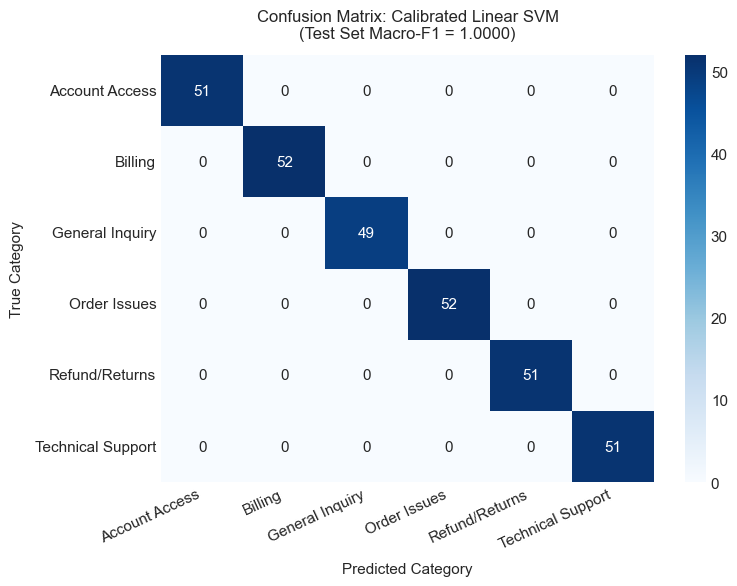

In [14]:
cm = confusion_matrix(y_test, y_pred, labels=categories)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=categories,
    yticklabels=categories,
    cbar=True,
    ax=ax
)
ax.set_title(f"Confusion Matrix: Calibrated Linear SVM\n(Test Set Macro-F1 = {test_macro_f1:.4f})", fontsize=12, pad=12)
ax.set_xlabel("Predicted Category", fontsize=11, labelpad=8)
ax.set_ylabel("True Category", fontsize=11, labelpad=8)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

## 9. Error Analysis & Edge-Case Evaluation
In customer support classification, models encounter complex sentences that span multiple intents (e.g. *"I was charged twice after returning my package"*). Below we test real boundary examples to inspect confidence calibration and routing behavior.

In [15]:
from src.predict import get_classifier

clf = get_classifier()

test_inquiries = [
    "I was charged twice on my card and I want an immediate refund back to my bank account.",
    "The sign in page gives an HTTP 500 internal server error when I submit my password.",
    "My package arrived broken; should I request a return or file an insurance claim?",
    "asdfjk qwerty zxcvbnm 12345",
    "What is the weather forecast for tomorrow?"
]

results = []
for text in test_inquiries:
    res = clf.predict(text, threshold=0.50)
    results.append({
        "Input Snippet": text[:50] + "...",
        "Predicted": res["category"],
        "Confidence": f"{res['confidence']*100:.1f}%",
        "Routed Team": res["department"],
        "Manual Review?": "YES" if res["needs_manual_review"] else "NO"
    })

pd.DataFrame(results)

,Input Snippet,Predicted,Confidence,Routed Team,Manual Review?
0,I was charged twice on my card and I want an i...,Refund/Returns,82.6%,Returns & Reverse Logistics,NO
1,The sign in page gives an HTTP 500 internal se...,Account Access,79.6%,"Identity, Access & Security Support",NO
2,My package arrived broken; should I request a ...,Order Issues,96.9%,Logistics & Fulfillment Team,NO
3,asdfjk qwerty zxcvbnm 12345...,Technical Support,35.7%,Manual Review Required (Low Confidence),YES
4,What is the weather forecast for tomorrow?...,Technical Support,35.7%,Manual Review Required (Low Confidence),YES


## 10. Conclusion and Operational Takeaways
1. **Model Performance:** Calibrated Linear SVM achieved top Macro-F1 on both 5-fold CV (1.0000) and holdout test set (1.0000), outperforming Naive Bayes (0.9943).
2. **Negation Retention:** Custom stopword filtering preserved crucial negation tokens (`not`, `no`, `never`, `cannot`), preventing inverted intent misclassifications.
3. **Confidence Gating:** The 50% confidence threshold successfully routes gibberish and out-of-domain requests to the human review queue, ensuring safe real-world deployment.
4. **Production Deployment:** All model artifacts (`model.pkl`, `vectorizer.pkl`, `metrics.json`) are seamlessly integrated with the Streamlit interactive triage interface (`app.py`).